# EOF Analysis of DO Anomalies
This notebook performs Empirical Orthogonal Function (EOF) analysis on **anomaly data**derived from the spatially interpolated DO dataset.**Key difference from `10_PCA_Analysis.ipynb`:**Instead of standardising raw DO values (`StandardScaler`), this notebook firstcomputes anomalies (departure from each station's temporal mean) and then appliesPCA. This is the standard EOF formulation on the covariance matrix, giving modesin the original physical units (mg/L).**Objective**: Identify dominant spatial and temporal patterns in DO *variability* across stations.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import sys
from pathlib import Path

# Ensure local scripts are importable
project_root = Path("../").resolve()
sys.path.append(str(project_root))

from utils.paths import ProjectPaths

# Configure plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## Parameters
This cell receives values from `dvc.yaml` / `params.yaml`. Tag it with **`parameters`** in Jupyter.

In [12]:
# Parameters
subset_dir = str(ProjectPaths.get_subset_dir('Summer', 'bottom'))  # default subset

## 1. Load Interpolated Data

In [13]:
# Load interpolated DO data from subset directory
from pathlib import Path
subset_path = Path(subset_dir)

interpolated_do_df = pd.read_csv(subset_path / "interpolated_do_df.csv", index_col=0)
interpolated_do_df.index = interpolated_do_df.index.astype(str).str.zfill(8)

print(f"Loaded from: {subset_path}")
print(f"Interpolated DO shape: {interpolated_do_df.shape}")
print(f"Remaining NaN values: {interpolated_do_df.isna().sum().sum()}")
interpolated_do_df.head()

Loaded from: /home/reyha/SIS_Analysis_WSL/data/processed/seasonal/summer_bottom
Interpolated DO shape: (124, 41)
Remaining NaN values: 26


,1982,1984,1985,1986,1987,1988,1989,1990,1991,1992,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
zettaicode,,,,,,,,,,,,,,,,,,,,,
00000272,4.0,1.1,1.9,2.1,0.800000,2.9,2.1,1.5,0.9,1.2,...,NaN,NaN,0.600000,0.700000,1.1,1.1,0.8,1.1,NaN,1.4
00000275,1.1,1.5,0.7,3.1,3.191709,1.1,1.4,0.3,1.1,1.0,...,4.277863,0.6,2.783987,2.183813,0.6,0.8,2.3,0.6,4.492493,1.2
00002725,5.6,4.8,3.9,9.5,6.200000,5.0,5.5,5.9,7.2,3.0,...,6.200000,6.1,5.900000,2.900000,6.6,6.6,3.1,6.4,6.500000,6.8
00002737,6.8,5.4,5.1,6.6,6.000000,4.7,6.0,4.6,4.9,7.5,...,6.500000,5.5,6.000000,6.200000,6.1,7.6,6.9,5.3,4.900000,6.3
00002744,6.6,3.6,4.8,5.8,5.800000,5.5,5.6,6.4,5.3,4.3,...,5.900000,6.3,5.800000,6.700000,6.2,6.5,6.0,6.1,6.400000,7.2


## 2. Compute Anomalies
Subtract each station's temporal mean (across all years) to obtain anomaly values.This removes the mean state and focuses the analysis on *variability*.

In [14]:
# Compute anomalies: subtract per-station temporal mean
station_means = interpolated_do_df.mean(axis=1)
anomaly_df = interpolated_do_df.sub(station_means, axis=0)

print(f"Station temporal means — min: {station_means.min():.3f}, max: {station_means.max():.3f}")
print(f"Anomaly value range: [{anomaly_df.min().min():.3f}, {anomaly_df.max().max():.3f}]")
print(f"Max |row-mean| of anomaly (should be ≈0): {anomaly_df.mean(axis=1).abs().max():.2e}")
anomaly_df.head()

Station temporal means — min: 1.919, max: 8.132
Anomaly value range: [-5.694, 6.254]
Max |row-mean| of anomaly (should be ≈0): 2.08e-15


,1982,1984,1985,1986,1987,1988,1989,1990,1991,1992,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
zettaicode,,,,,,,,,,,,,,,,,,,,,
00000272,2.065789,-0.834211,-0.034211,0.165789,-1.134211,0.965789,0.165789,-0.434211,-1.034211,-0.734211,...,NaN,NaN,-1.334211,-1.234211,-0.834211,-0.834211,-1.134211,-0.834211,NaN,-0.534211
00000275,-0.819186,-0.419186,-1.219186,1.180814,1.272523,-0.819186,-0.519186,-1.619186,-0.819186,-0.919186,...,2.358677,-1.319186,0.864802,0.264627,-1.319186,-1.119186,0.380814,-1.319186,2.573308,-0.719186
00002725,-0.112195,-0.912195,-1.812195,3.787805,0.487805,-0.712195,-0.212195,0.187805,1.487805,-2.712195,...,0.487805,0.387805,0.187805,-2.812195,0.887805,0.887805,-2.612195,0.687805,0.787805,1.087805
00002737,1.073171,-0.326829,-0.626829,0.873171,0.273171,-1.026829,0.273171,-1.126829,-0.826829,1.773171,...,0.773171,-0.226829,0.273171,0.473171,0.373171,1.873171,1.173171,-0.426829,-0.826829,0.573171
00002744,0.595122,-2.404878,-1.204878,-0.204878,-0.204878,-0.504878,-0.404878,0.395122,-0.704878,-1.704878,...,-0.104878,0.295122,-0.204878,0.695122,0.195122,0.495122,-0.004878,0.095122,0.395122,1.195122


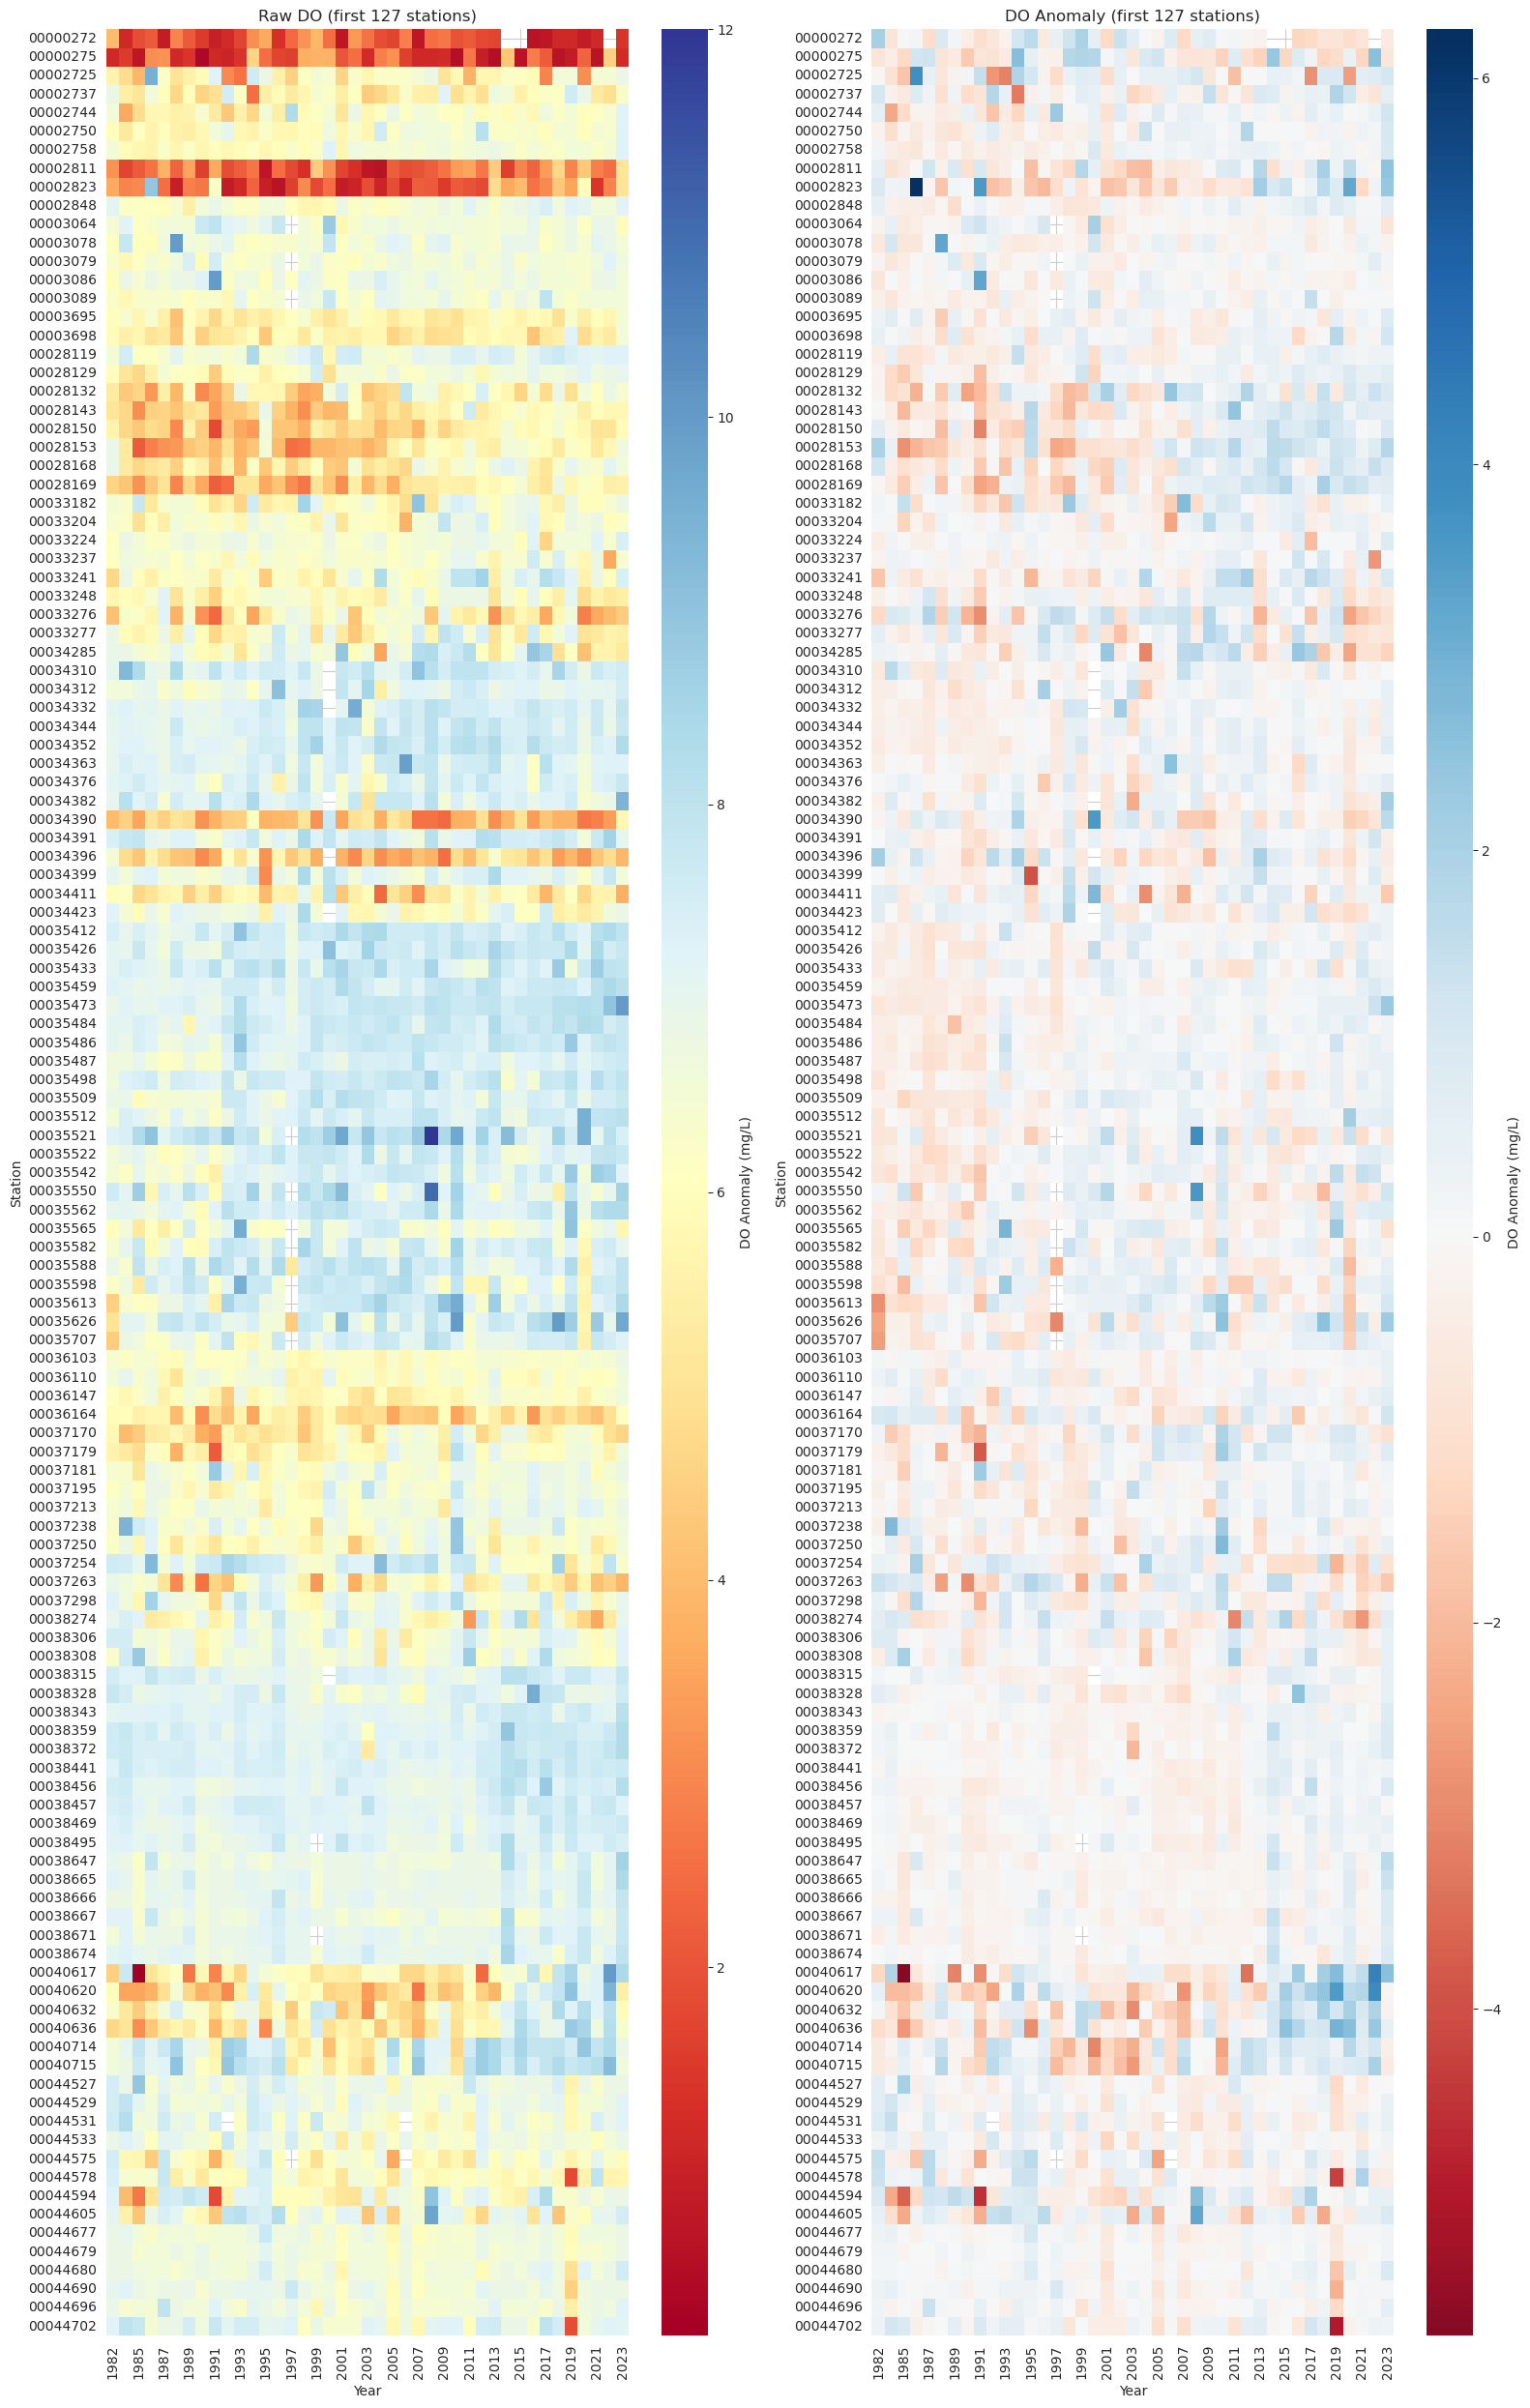

In [15]:
# Side-by-side heatmap: raw data vs anomaly data
# Increased figsize to handle many stations gracefully
fig, axes = plt.subplots(1, 2, figsize=(16, 25))

# Plot 1: Raw DO - Colorbar removed (cbar=False)
sns.heatmap(interpolated_do_df.iloc[:127], ax=axes[0], cmap='RdYlBu', center=None,
            cbar_kws={'aspect': 50, 'label': 'DO Anomaly (mg/L)'})
axes[0].set_title('Raw DO (first 127 stations)')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Station')

# Plot 2: DO Anomaly - Colorbar made thinner using cbar_kws aspect
sns.heatmap(anomaly_df.iloc[:127], ax=axes[1], cmap='RdBu', center=0, 
            cbar_kws={'aspect': 50, 'label': 'DO Anomaly (mg/L)'})
axes[1].set_title('DO Anomaly (first 127 stations)')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Station')

plt.tight_layout()
plt.show()

## 3. NaN Handling & PCA-Ready Matrix
Drop stations with any remaining NaN values, then transpose so that PCA receives a **(years × stations)** matrix.**No `StandardScaler`** is applied — the anomalies are already centred by construction.

In [16]:
# Drop stations with any remaining NaN
anomaly_clean = anomaly_df.dropna()
print(f"Stations before NaN drop: {len(anomaly_df)}")
print(f"Stations after NaN drop:  {len(anomaly_clean)}")

# Transpose: PCA expects (samples × features) = (years × stations)
pca_ready_df = anomaly_clean.T
print(f"\nPCA-ready matrix shape: {pca_ready_df.shape}")
print(f"  (years={pca_ready_df.shape[0]}, stations={pca_ready_df.shape[1]})")

Stations before NaN drop: 124
Stations after NaN drop:  102

PCA-ready matrix shape: (41, 102)
  (years=41, stations=102)


## 4. Perform PCA (EOF Decomposition)

In [17]:
# Perform PCA on anomaly matrix (EOF decomposition)
pca = PCA()
scores = pca.fit_transform(pca_ready_df)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Create scores DataFrame (temporal coefficients / principal components)
scores_df = pd.DataFrame(
    scores,
    index=pca_ready_df.index,
    columns=[f'PC{i+1}' for i in range(scores.shape[1])]
)

print(f"Number of components: {pca.n_components_}")
print(f"Variance explained by PC1: {explained_variance[0]*100:.2f}%")
print(f"Variance explained by PC2: {explained_variance[1]*100:.2f}%")
print(f"Variance explained by PC3: {explained_variance[2]*100:.2f}%")

Number of components: 41
Variance explained by PC1: 18.79%
Variance explained by PC2: 9.36%
Variance explained by PC3: 6.89%


## 5. Scree Plot

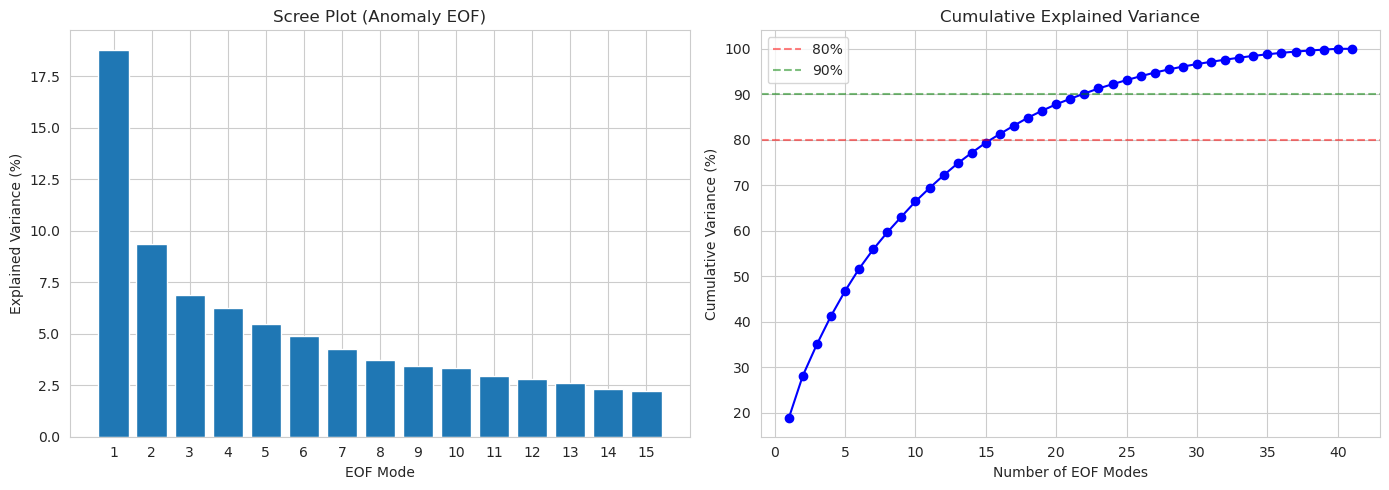

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart of individual variance
n_show = min(15, len(explained_variance))
ax1.bar(range(1, n_show+1), explained_variance[:n_show]*100)
ax1.set_xlabel('EOF Mode')
ax1.set_ylabel('Explained Variance (%)')
ax1.set_title('Scree Plot (Anomaly EOF)')
ax1.set_xticks(range(1, n_show+1))

# Cumulative variance
ax2.plot(range(1, len(cumulative_variance)+1), cumulative_variance*100, 'bo-')
ax2.axhline(y=80, color='r', linestyle='--', alpha=0.5, label='80%')
ax2.axhline(y=90, color='g', linestyle='--', alpha=0.5, label='90%')
ax2.set_xlabel('Number of EOF Modes')
ax2.set_ylabel('Cumulative Variance (%)')
ax2.set_title('Cumulative Explained Variance')
ax2.legend()

plt.tight_layout()
plt.show()

## 6. Variance Explained Table

In [19]:
# Variance explained table
variance_table = pd.DataFrame({
    'EOF Mode': [f'EOF{i+1}' for i in range(min(10, len(explained_variance)))],
    'Explained Variance (%)': explained_variance[:10] * 100,
    'Cumulative (%)': cumulative_variance[:10] * 100
})
variance_table.style.format({
    'Explained Variance (%)': '{:.2f}',
    'Cumulative (%)': '{:.2f}'
}).hide(axis='index')

EOF Mode,Explained Variance (%),Cumulative (%)
EOF1,18.79,18.79
EOF2,9.36,28.15
EOF3,6.89,35.04
EOF4,6.23,41.27
EOF5,5.49,46.76
EOF6,4.90,51.66
EOF7,4.25,55.91
EOF8,3.74,59.65
EOF9,3.43,63.08
EOF10,3.35,66.44


## 7. Temporal Scores (EOF Time Series)
The temporal coefficients (scores) show how each EOF mode varies year-to-year.

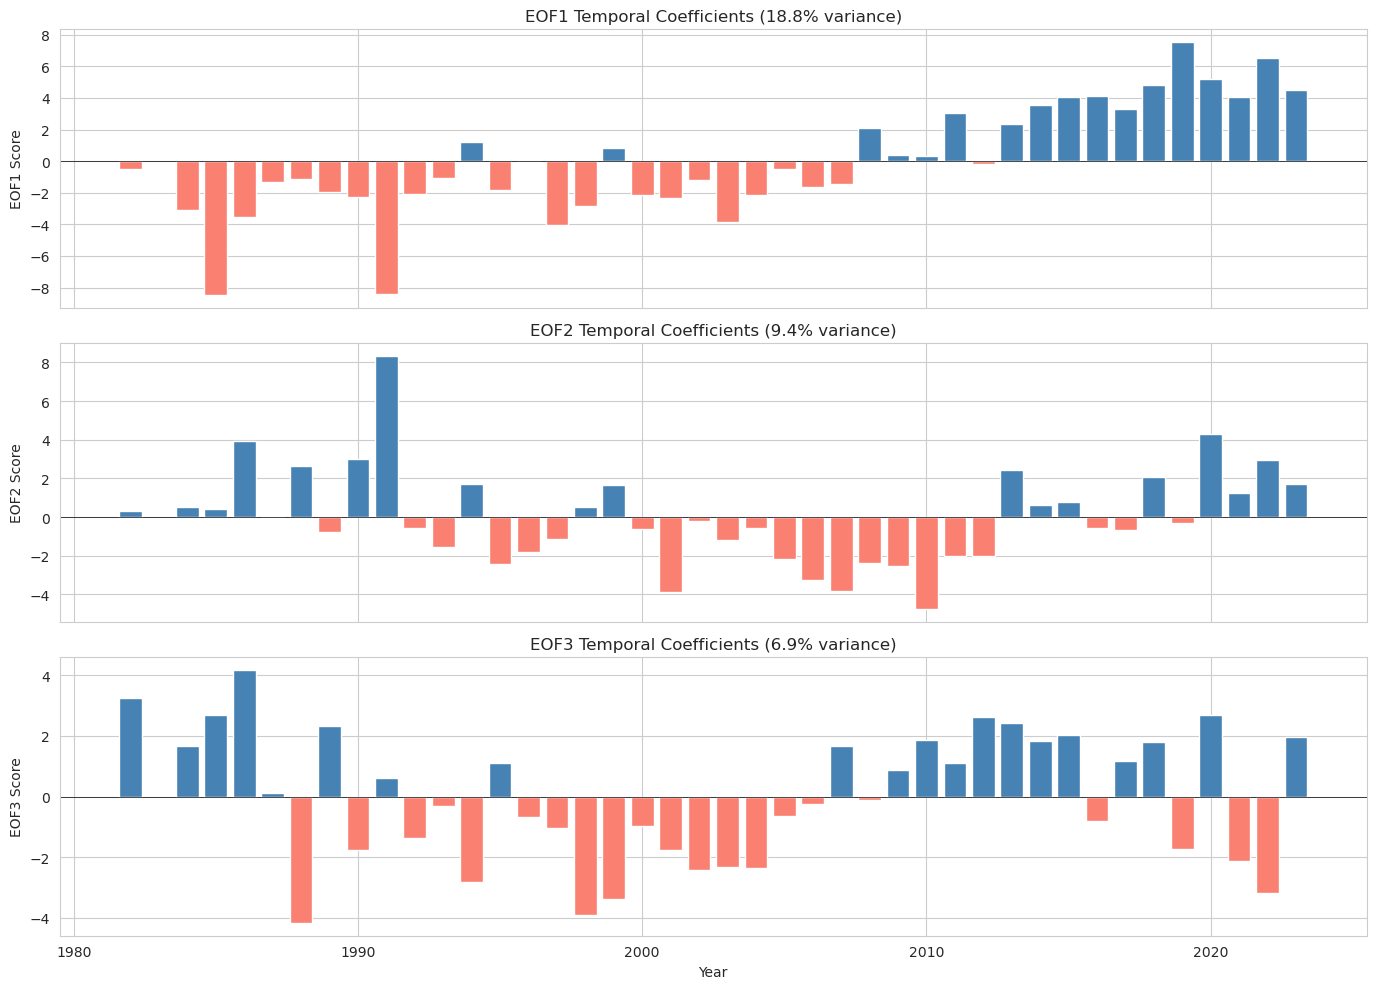

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for i, ax in enumerate(axes):
    pc_col = f'PC{i+1}'
    years = scores_df.index.astype(int)
    values = scores_df[pc_col]
    
    ax.bar(years, values, color=['steelblue' if v >= 0 else 'salmon' for v in values])
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.set_ylabel(f'EOF{i+1} Score')
    ax.set_title(f'EOF{i+1} Temporal Coefficients ({explained_variance[i]*100:.1f}% variance)')

axes[-1].set_xlabel('Year')
plt.tight_layout()
plt.show()

## 8. Spatial Loadings
Station loadings (eigenvectors) — top 10 highest and lowest for each EOF mode.

In [21]:
# Get loadings (components)
loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_ready_df.columns,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

# Create loadings DataFrame for saving
loadings_df = loadings.copy()
loadings_df.index.name = 'zettaicode'

print(f"Loadings shape: {loadings.shape}\n")

for pc_idx in range(min(3, pca.n_components_)):
    pc_col = f'PC{pc_idx+1}'
    
    top10_high = loadings[pc_col].nlargest(10).reset_index()
    top10_high.columns = ['Station_ID', f'{pc_col}_Loading']
    top10_high['Rank'] = range(1, 11)
    top10_high['Type'] = 'Highest'
    
    top10_low = loadings[pc_col].nsmallest(10).reset_index()
    top10_low.columns = ['Station_ID', f'{pc_col}_Loading']
    top10_low['Rank'] = range(1, 11)
    top10_low['Type'] = 'Lowest'
    
    summary = pd.concat([top10_high, top10_low], ignore_index=True)
    summary = summary[['Rank', 'Type', 'Station_ID', f'{pc_col}_Loading']]
    
    print("=" * 50)
    print(f"EOF{pc_idx+1}: Top 10 Highest & Lowest Loading Stations")
    print("=" * 50)
    display(summary.style.format({f'{pc_col}_Loading': '{:.4f}'}).hide(axis='index'))

Loadings shape: (102, 41)

EOF1: Top 10 Highest & Lowest Loading Stations


Rank,Type,Station_ID,PC1_Loading
1,Highest,00040617,0.3415
2,Highest,00040620,0.3307
3,Highest,00040636,0.3158
4,Highest,00028153,0.2506
5,Highest,00028169,0.2494
6,Highest,00040632,0.2409
7,Highest,00028143,0.2071
8,Highest,00044594,0.1949
9,Highest,00028168,0.1876
10,Highest,00028150,0.1813


EOF2: Top 10 Highest & Lowest Loading Stations


Rank,Type,Station_ID,PC2_Loading
1,Highest,00002823,0.4537
2,Highest,00040632,0.1939
3,Highest,00002811,0.1545
4,Highest,00003086,0.1308
5,Highest,00002725,0.1306
6,Highest,00040620,0.1236
7,Highest,00040636,0.1113
8,Highest,00037181,0.0864
9,Highest,00040617,0.0852
10,Highest,00044702,0.0606


EOF3: Top 10 Highest & Lowest Loading Stations


Rank,Type,Station_ID,PC3_Loading
1,Highest,00002823,0.4339
2,Highest,00037263,0.2862
3,Highest,00028153,0.2036
4,Highest,00028150,0.1933
5,Highest,00002811,0.1931
6,Highest,00028169,0.1758
7,Highest,00036164,0.1677
8,Highest,00037250,0.1633
9,Highest,00037238,0.1602
10,Highest,00040714,0.1422


## 9. Station Eigenvectors

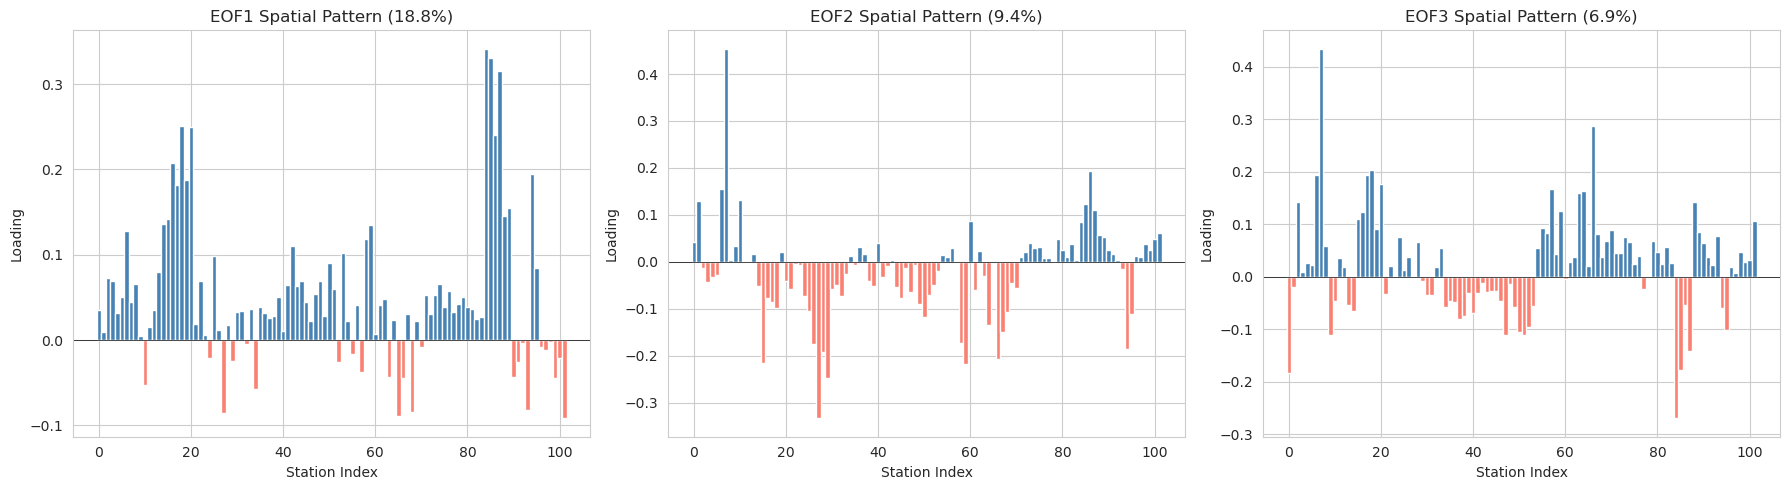

In [22]:
# Eigenvectors: spatial patterns for first 3 EOF modes
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, ax in enumerate(axes):
    pc_col = f'PC{i+1}'
    vals = loadings[pc_col].values
    
    colors = ['steelblue' if v >= 0 else 'salmon' for v in vals]
    ax.bar(range(len(vals)), vals, color=colors, width=1.0)
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.set_xlabel('Station Index')
    ax.set_ylabel('Loading')
    ax.set_title(f'EOF{i+1} Spatial Pattern ({explained_variance[i]*100:.1f}%)')

plt.tight_layout()
plt.show()

Merge Result: 102 stations matched out of 102 PCA stations.


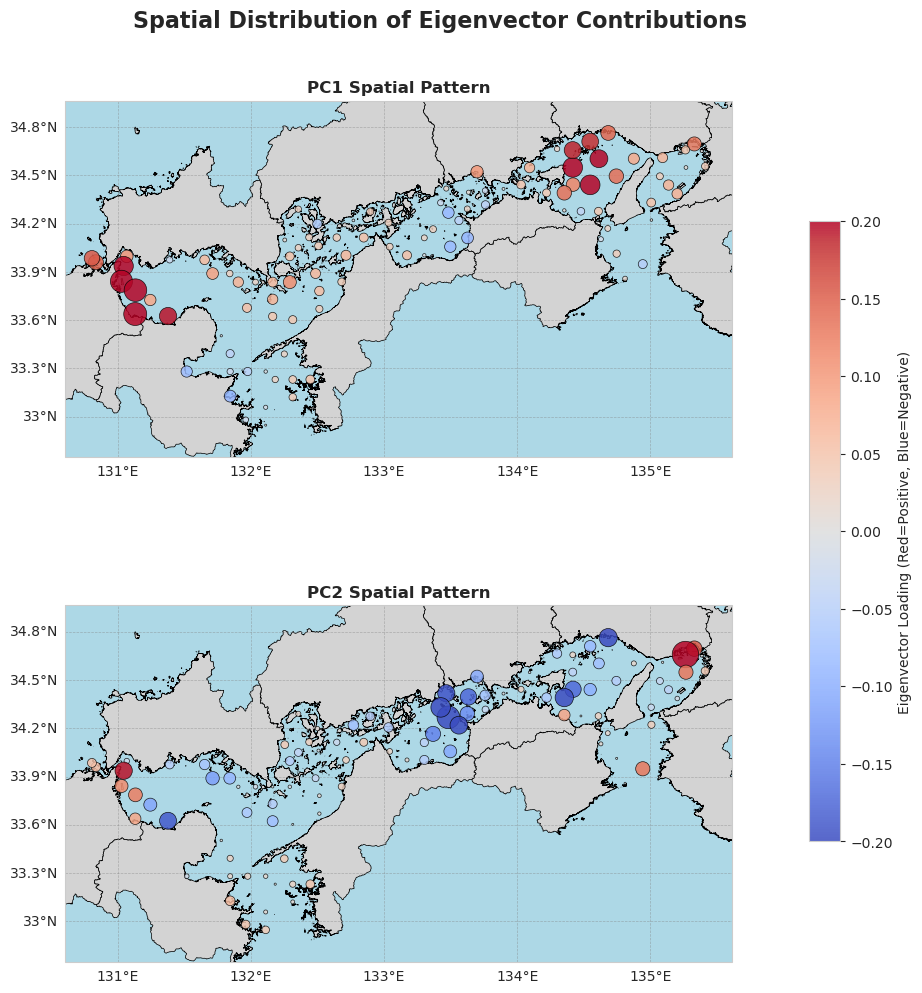

In [25]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Import pipeline standard tools (NOTE: cfeature is intentionally omitted)
from utils.paths import ProjectPaths
from scripts.mapping_config import MappingConfig

# 1. Get Eigenvectors (Loadings)
pc1_loadings = pca.components_[0]
pc2_loadings = pca.components_[1]

# 2. Get Station Coordinates
gdf_path = ProjectPaths.PROCESSED_DATA_DIR / "merged_gdf.feather"
gdf = gpd.read_feather(gdf_path)

# 3. Create loadings DataFrame
station_ids = pca_ready_df.columns.tolist()  # FIX: use .columns, not .index

loadings_df = pd.DataFrame({
    'zettaicode': station_ids,
    'PC1_Loading': pc1_loadings,
    'PC2_Loading': pc2_loadings
})

gdf_unique_stations = gdf.drop_duplicates(subset='zettaicode')[['zettaicode', 'geometry']].copy()
loadings_df['zettaicode'] = loadings_df['zettaicode'].astype(str)
gdf_unique_stations['zettaicode'] = gdf_unique_stations['zettaicode'].astype(str)
loadings_map_data = gdf_unique_stations.merge(loadings_df, on='zettaicode', how='inner')

print(f"Merge Result: {len(loadings_map_data)} stations matched out of {len(station_ids)} PCA stations.")

# 4. Load Custom Land Boundary
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary.shp"
sis_land_boundary = gpd.read_file(land_boundary_path)
if sis_land_boundary.crs != "EPSG:4326":
    sis_land_boundary = sis_land_boundary.to_crs("EPSG:4326")

# 5. Plotting (Vertical Stack)
fig, axes = plt.subplots(2, 1, figsize=(10, 12), subplot_kw={'projection': ccrs.PlateCarree()})

# Title closer to the top plot 
fig.suptitle('Spatial Distribution of Eigenvector Contributions', fontsize=16, fontweight='bold', y=0.95)

components = [('PC1_Loading', 'PC1'), ('PC2_Loading', 'PC2')]

for ax, (col, title) in zip(axes, components):
    # Set Ocean Background dynamically
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    
    # Establish bounds with padding
    pad = 0.2
    min_lon, min_lat, max_lon, max_lat = loadings_map_data.total_bounds
    ax.set_extent([min_lon - pad, max_lon + pad, min_lat - pad, max_lat + pad], crs=ccrs.PlateCarree())

    # Plot intricate SIS land border instead of coarse global cfeature.LAND
    sis_land_boundary.plot(
        ax=ax,
        facecolor=MappingConfig.COLOR_LAND,
        edgecolor=MappingConfig.COLOR_LAND_EDGE,
        linewidth=MappingConfig.LINEWIDTH_LAND,
        transform=ccrs.PlateCarree(),
        zorder=MappingConfig.ZORDER_LAND
    )

    # MappingConfig compliant Gridlines
    gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE, 
                      color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA, 
                      linewidth=MappingConfig.GRID_LINEWIDTH, zorder=MappingConfig.ZORDER_GRIDLINES)
    gl.top_labels = False
    gl.right_labels = False

    # Map the Eigenvectors
    sc = ax.scatter(
        loadings_map_data.geometry.x,
        loadings_map_data.geometry.y,
        c=loadings_map_data[col],
        s=loadings_map_data[col].abs() * 800,  # Size scales with absolute loading value
        cmap='coolwarm',
        edgecolor='k',
        linewidth=0.5,
        alpha=0.85,
        transform=ccrs.PlateCarree(),
        vmin=-0.2, vmax=0.2,
        zorder=MappingConfig.ZORDER_PREDICTED
    )
    ax.set_title(f'{title} Spatial Pattern', fontsize=12, fontweight='bold')

# Reduce vertical spacing between subplots
plt.subplots_adjust(hspace=0.08, top=0.92)

# Vertical colorbar adjusted to the right
cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), orientation='vertical', fraction=0.04, pad=0.1)
cbar.set_label('Eigenvector Loading (Red=Positive, Blue=Negative)')

plt.show()

## 10. Summary Statistics

In [13]:
# Determine number of PCs needed for 80% and 90% variance
n_80 = np.argmax(cumulative_variance >= 0.80) + 1
n_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("=" * 50)
print("EOF ANALYSIS SUMMARY (ANOMALY DATA)")
print("=" * 50)
print(f"Total stations analysed: {len(pca_ready_df.columns)}")
print(f"Total years: {len(pca_ready_df.index)}")
print(f"\nVariance explained by EOF1: {explained_variance[0]*100:.2f}%")
print(f"Variance explained by EOF2: {explained_variance[1]*100:.2f}%")
print(f"Variance explained by EOF3: {explained_variance[2]*100:.2f}%")
print(f"\nComponents needed for 80% variance: {n_80}")
print(f"Components needed for 90% variance: {n_90}")
print("=" * 50)

EOF ANALYSIS SUMMARY (ANOMALY DATA)
Total stations analysed: 102
Total years: 41

Variance explained by EOF1: 18.79%
Variance explained by EOF2: 9.36%
Variance explained by EOF3: 6.89%

Components needed for 80% variance: 16
Components needed for 90% variance: 22


## 11. Correlation with Decorrelation Scale
Test whether stations with high/low decorrelation scales show different EOF loading patterns.

In [14]:
# Merge EOF loadings with decorrelation scale data
loadings_analysis = loadings[['PC1', 'PC2', 'PC3']].copy()
loadings_analysis.index.name = 'Station_ID'

# Load decorrelation data from subset directory
decorrelation_df = pd.read_csv(Path(subset_dir) / "stations_decorrelation_scale.csv")
decorrelation_df['Station_ID'] = decorrelation_df['Station_ID'].astype(str).str.zfill(8)
decorrelation_df = decorrelation_df.set_index('Station_ID')

# Merge
analysis_df = loadings_analysis.join(decorrelation_df['Decorrelation_Scale_km'], how='inner')
print(f"Stations with both EOF loadings and decorrelation scale: {len(analysis_df)}")
analysis_df.head()

Stations with both EOF loadings and decorrelation scale: 102


,PC1,PC2,PC3,Decorrelation_Scale_km
Station_ID,,,,
00000275,0.035019,0.041941,-0.183881,9.509381
00002725,0.009358,0.130560,-0.020577,8.890848
00002737,0.072948,-0.013678,0.141527,4.851579
00002744,0.069514,-0.042596,0.008320,5.398100
00002750,0.031267,-0.031524,0.025594,7.102060


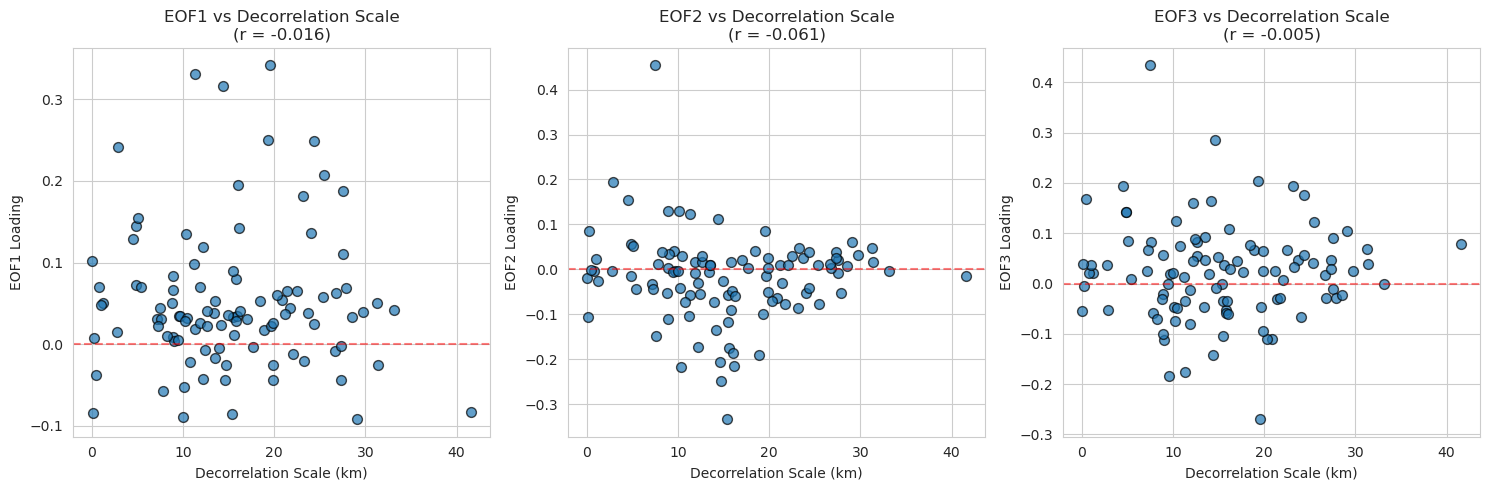

In [15]:
# Scatter plots: Decorrelation Scale vs EOF Loadings
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, ax in enumerate(axes):
    pc_col = f'PC{i+1}'
    
    ax.scatter(analysis_df['Decorrelation_Scale_km'], analysis_df[pc_col],
              alpha=0.7, edgecolor='black', s=50)
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.5)
    
    corr = analysis_df['Decorrelation_Scale_km'].corr(analysis_df[pc_col])
    ax.set_xlabel('Decorrelation Scale (km)')
    ax.set_ylabel(f'EOF{i+1} Loading')
    ax.set_title(f'EOF{i+1} vs Decorrelation Scale\n(r = {corr:.3f})')

plt.tight_layout()
plt.show()

25th percentile decorrelation scale: 9.44 km
75th percentile decorrelation scale: 21.31 km

Stations in Low group:  26
Stations in High group: 26


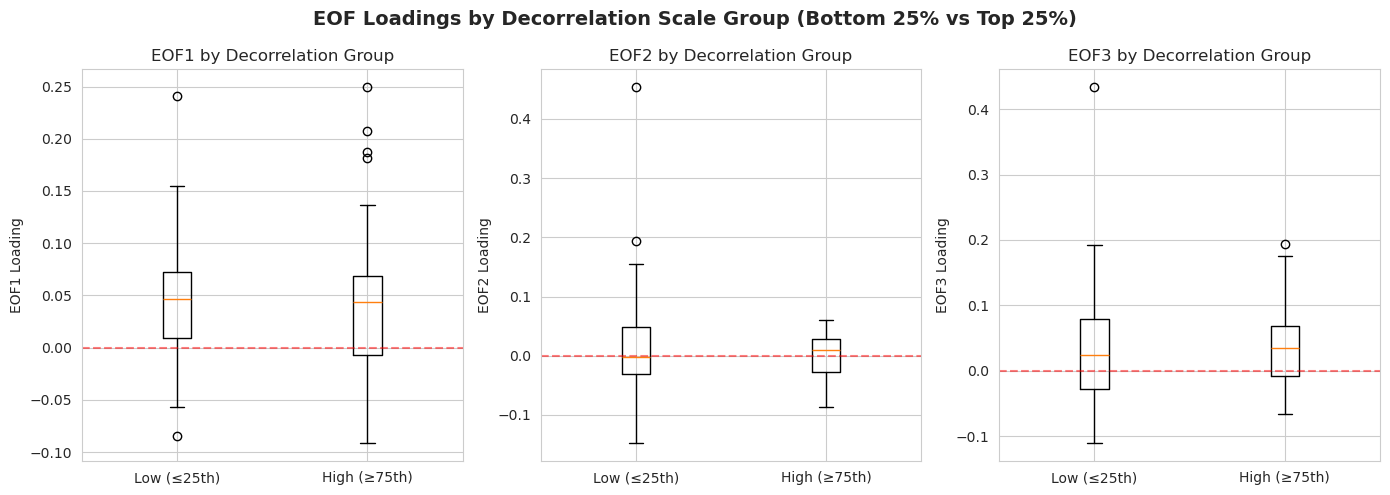

In [16]:
# Divide stations into extreme groups: bottom 25% vs top 25% of decorrelation scale
q25 = analysis_df['Decorrelation_Scale_km'].quantile(0.25)
q75 = analysis_df['Decorrelation_Scale_km'].quantile(0.75)
print(f"25th percentile decorrelation scale: {q25:.2f} km")
print(f"75th percentile decorrelation scale: {q75:.2f} km")

def assign_extreme_group(val):
    if val <= q25:
        return 'Low (≤ 25th pctl)'
    elif val >= q75:
        return 'High (≥ 75th pctl)'
    else:
        return 'Middle (excluded)'

analysis_df['Scale_Group'] = analysis_df['Decorrelation_Scale_km'].apply(assign_extreme_group)
extreme_df = analysis_df[analysis_df['Scale_Group'] != 'Middle (excluded)'].copy()

print(f"\nStations in Low group:  {len(extreme_df[extreme_df['Scale_Group'] == 'Low (≤ 25th pctl)'])}")
print(f"Stations in High group: {len(extreme_df[extreme_df['Scale_Group'] == 'High (≥ 75th pctl)'])}")

# Box plot comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for i, ax in enumerate(axes):
    pc_col = f'PC{i+1}'
    high_group = extreme_df[extreme_df['Scale_Group'] == 'High (≥ 75th pctl)'][pc_col]
    low_group = extreme_df[extreme_df['Scale_Group'] == 'Low (≤ 25th pctl)'][pc_col]
    
    ax.boxplot([low_group, high_group], tick_labels=['Low (≤25th)', 'High (≥75th)'])
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.5)
    ax.set_ylabel(f'EOF{i+1} Loading')
    ax.set_title(f'EOF{i+1} by Decorrelation Group')

plt.suptitle('EOF Loadings by Decorrelation Scale Group (Bottom 25% vs Top 25%)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [17]:
from scipy import stats

print("=== T-Test Results (Extreme Decorrelation Scale Groups) ===\n")

for i in range(3):
    pc_col = f'PC{i+1}'
    high_group = extreme_df[extreme_df['Scale_Group'] == 'High (≥ 75th pctl)'][pc_col]
    low_group = extreme_df[extreme_df['Scale_Group'] == 'Low (≤ 25th pctl)'][pc_col]
    
    t_stat, p_value = stats.ttest_ind(high_group, low_group)
    mean_high = high_group.mean()
    mean_low = low_group.mean()
    opposite = (mean_high > 0 and mean_low < 0) or (mean_high < 0 and mean_low > 0)
    
    print(f"EOF{i+1}:")
    print(f"  Mean (High Scale, ≥75th pctl): {mean_high:.4f}")
    print(f"  Mean (Low Scale, ≤25th pctl):  {mean_low:.4f}")
    print(f"  Opposite signs?    {'YES ✓' if opposite else 'NO'}")
    print(f"  T-statistic: {t_stat:.3f}, p-value: {p_value:.4f}")
    print(f"  Significant (p<0.05)? {'YES ✓' if p_value < 0.05 else 'NO'}")
    print()

=== T-Test Results (Extreme Decorrelation Scale Groups) ===

EOF1:
  Mean (High Scale, ≥75th pctl): 0.0529
  Mean (Low Scale, ≤25th pctl):  0.0494
  Opposite signs?    NO
  T-statistic: 0.167, p-value: 0.8683
  Significant (p<0.05)? NO

EOF2:
  Mean (High Scale, ≥75th pctl): -0.0006
  Mean (Low Scale, ≤25th pctl):  0.0243
  Opposite signs?    YES ✓
  T-statistic: -1.026, p-value: 0.3100
  Significant (p<0.05)? NO

EOF3:
  Mean (High Scale, ≥75th pctl): 0.0393
  Mean (Low Scale, ≤25th pctl):  0.0405
  Opposite signs?    NO
  T-statistic: -0.046, p-value: 0.9636
  Significant (p<0.05)? NO



## 12. Save ResultsSave EOF analysis outputs to the subset directory.

In [18]:
# --- Save EOF Results to Subset Directory ---
subset_path = Path(subset_dir)

# 1. Save Temporal Scores (EOF values for each year)
scores_path = subset_path / "eof_anomaly_scores.csv"
scores_df.to_csv(scores_path)
print(f"Saved Scores to: {scores_path}")

# 2. Save Spatial Loadings (Contribution of each station to EOFs)
loadings_path = subset_path / "eof_anomaly_loadings.csv"
loadings_df.to_csv(loadings_path)
print(f"Saved Loadings to: {loadings_path}")

# 3. Save Variance Explained Stats
variance_df = pd.DataFrame({
    'EOF_Mode': [f"EOF{i+1}" for i in range(len(explained_variance))],
    'Explained_Variance': explained_variance,
    'Cumulative_Variance': cumulative_variance
})
variance_path = subset_path / "eof_anomaly_variance.csv"
variance_df.to_csv(variance_path, index=False)
print(f"Saved Variance Stats to: {variance_path}")

Saved Scores to: /home/reyha/SIS_Analysis_WSL/data/processed/seasonal/summer_bottom/eof_anomaly_scores.csv


Saved Loadings to: /home/reyha/SIS_Analysis_WSL/data/processed/seasonal/summer_bottom/eof_anomaly_loadings.csv
Saved Variance Stats to: /home/reyha/SIS_Analysis_WSL/data/processed/seasonal/summer_bottom/eof_anomaly_variance.csv
